# Extracting the best-focus slice from a brightfield z-stack

This notebook walks through what [`extract_focused_slices.py`](extract_focused_slices.py) does to a single ND2 file, step by step. The script is normally run as a batch CLI over a directory of z-stacks, but here we unpack its internals on one example image so you can see how the in-focus slice is chosen and exported.

The pipeline is: load the brightfield z-stack, restrict attention to a circular well ROI, score each z-slice by its Sobel edge energy inside that ROI, pick the sharpest slice, then rescale it by percentile and save it as an 8-bit image. Optionally the matching fluorescence slice at the same z-index is exported too.

## Setup

We import the helper functions straight from `extract_focused_slices.py` so the notebook exercises the exact same code the CLI uses. Run the notebook from the repository root or from the `image-processing/` directory; the cell below locates the script either way and adds it to the import path.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import skimage as ski

# Locate extract_focused_slices.py whether the kernel started at the repo root
# or inside image-processing/, then make it importable.
_cwd = Path.cwd()
for _candidate in (_cwd, _cwd / "image-processing"):
    if (_candidate / "extract_focused_slices.py").exists():
        script_dir = _candidate
        break
else:
    raise FileNotFoundError(
        "Could not find extract_focused_slices.py. Run this notebook from the "
        "repository root or from the image-processing/ directory."
    )

sys.path.insert(0, str(script_dir))
import extract_focused_slices as efs

data_dir = script_dir / "data"
print(f"Script directory: {script_dir}")
print(f"Data directory:   {data_dir}")

Script directory: /Users/ryanlane/Repositories/menisquish-flat-agar/image-processing
Data directory:   /Users/ryanlane/Repositories/menisquish-flat-agar/image-processing/data


## Load the ND2 z-stack

We use one of the example wells shipped under `data/` — `WellH03` from the `20260605_152922_245` acquisition, which appears in the pub as figure 2 (worm-plates B) and figure 3 (optimization C, day 3). A `MicroscopyImage` exposes the raw intensities plus metadata; we pull out just the brightfield channel, which is a `(Z, Y, X)` stack of 16-bit slices at different focal planes.

In [ ]:
from arcadia_microscopy_tools import MicroscopyImage

nd2_path = (
    data_dir / "20260605_152922_245" / "WellH03_Channelbrightfield,TRITC_Seq0061.nd2"
)

zstack = MicroscopyImage.from_nd2_path(nd2_path)
print("Dimension sizes:", zstack.sizes)
print("Channels:       ", [ch.name for ch in zstack.channels])

intensities = zstack.get_channel_intensities("BRIGHTFIELD")
print("Brightfield stack shape:", intensities.shape, "dtype:", intensities.dtype)
n_slices = intensities.shape[0]

Dimension sizes: {'Z': 11, 'C': 2, 'Y': 2100, 'X': 2100}
Channels:        ['BRIGHTFIELD', 'TRITC']
Brightfield stack shape: (11, 2100, 2100) dtype: uint16


## Define the circular well ROI

The well is a circle near the center of the frame, and the corners contain plate edges and vignetting that would confuse a focus metric. The script centers a disk on the image and sets its radius to half the shorter image dimension minus a fixed margin (`--radius-margin`, default 250 px). Everything outside that disk is ignored when scoring focus. Below we compute the same geometry and overlay it on the middle slice.

ROI center=(1050, 1050), radius=800 px


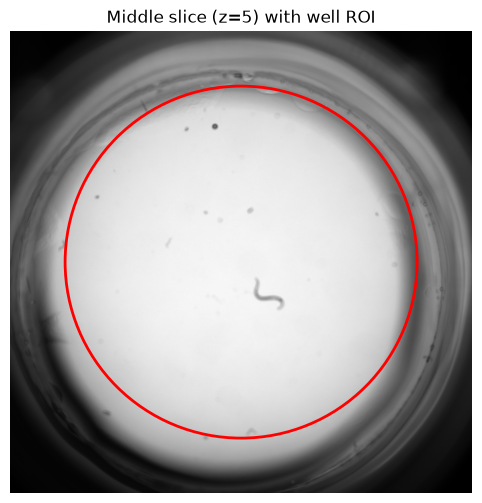

In [3]:
radius_margin = 250  # matches the CLI default (--radius-margin)

cy = intensities.shape[1] // 2
cx = intensities.shape[2] // 2
radius = min(intensities.shape[1:3]) // 2 - radius_margin
print(f"ROI center=({cy}, {cx}), radius={radius} px")

mid = n_slices // 2
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(intensities[mid], cmap="gray")
ax.add_patch(plt.Circle((cx, cy), radius, fill=False, color="red", lw=2))
ax.set_title(f"Middle slice (z={mid}) with well ROI")
ax.axis("off")
plt.show()

## Score focus with Sobel edge energy

A sharp, in-focus slice has crisp edges and therefore a large response to a Sobel edge filter; a blurry slice has weak edges. For each z-slice the script masks everything outside the ROI to `NaN`, downsamples by `--edge-downsample` (default 4) for speed, applies a Sobel filter, and sums the edge magnitude inside the ROI. The slice with the greatest total edge energy is declared in focus.

`efs.find_focus_index` returns just that index. Here we also reproduce the per-slice edge-energy curve so we can see the focus peak, using the script's own `apply_circular_mask` and `downsample` helpers.

In-focus z-index: 9


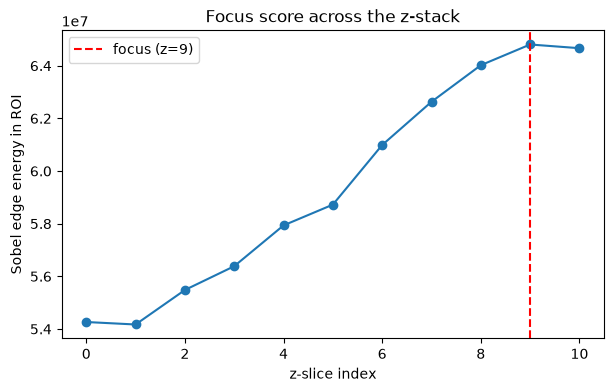

In [4]:
edge_downsample = 4  # matches the CLI default (--edge-downsample)

# The one-liner the script actually uses to pick the focus slice:
focus_index = efs.find_focus_index(intensities, cy, cx, radius, edge_downsample)
print(f"In-focus z-index: {focus_index}")

# Reproduce the full per-slice edge-energy curve for visualization.
masked = efs.apply_circular_mask(intensities, cy, cx, radius)
edge_energy = np.array(
    [np.nansum(ski.filters.sobel(efs.downsample(sl, edge_downsample))) for sl in masked]
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(n_slices), edge_energy, "-o")
ax.axvline(focus_index, color="red", ls="--", label=f"focus (z={focus_index})")
ax.set_xlabel("z-slice index")
ax.set_ylabel("Sobel edge energy in ROI")
ax.set_title("Focus score across the z-stack")
ax.legend()
plt.show()

## Compare slices across the stack

To sanity-check the choice, we view the sharpest slice next to slices near the top and bottom of the stack. The focus slice should look visibly crisper than its neighbors.

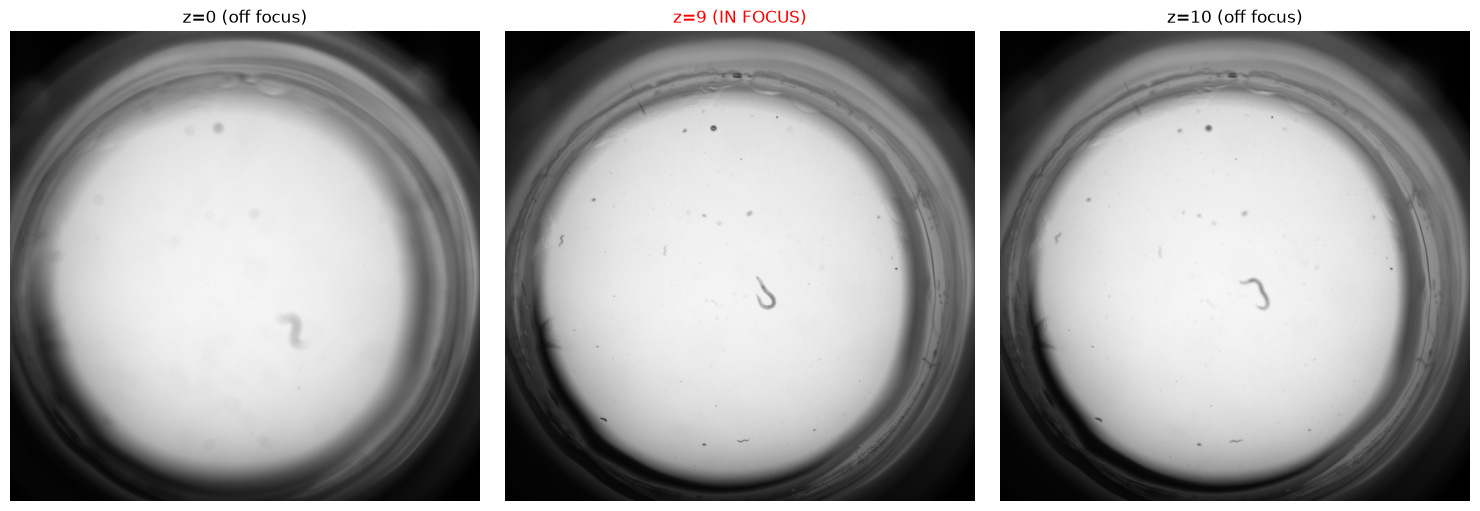

In [5]:
show_indices = sorted({0, focus_index, n_slices - 1})

fig, axes = plt.subplots(1, len(show_indices), figsize=(5 * len(show_indices), 5))
for ax, z in zip(np.atleast_1d(axes), show_indices):
    ax.imshow(intensities[z], cmap="gray")
    label = "IN FOCUS" if z == focus_index else "off focus"
    ax.set_title(f"z={z} ({label})", color="red" if z == focus_index else "black")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Rescale and export the focused slice

The chosen slice is contrast-stretched by clipping to a percentile range (`--percentile-range`, default 0.1–99.9) to drop outliers, then rescaled to the full 0–255 range and cast to 8-bit. This is the image the CLI writes to disk. We build the same `rescale_by_percentile` pipeline the script uses and apply the script's `to_ubyte` helper.

Exported image shape: (2100, 2100) dtype: uint8


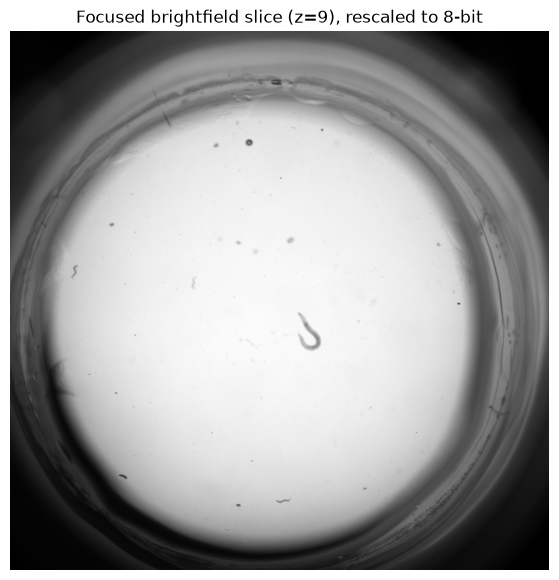

In [6]:
from arcadia_microscopy_tools import ImageOperation, Pipeline
from arcadia_microscopy_tools.operations import rescale_by_percentile

percentile_range = (0.1, 99.9)  # matches the CLI default (--percentile-range)

preprocess = Pipeline(
    [ImageOperation(rescale_by_percentile, percentile_range=percentile_range)]
)

focused = preprocess(intensities[focus_index])
focused_u8 = efs.to_ubyte(focused)
print("Exported image shape:", focused_u8.shape, "dtype:", focused_u8.dtype)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(focused_u8, cmap="gray", vmin=0, vmax=255)
ax.set_title(f"Focused brightfield slice (z={focus_index}), rescaled to 8-bit")
ax.axis("off")
plt.show()

## Matching fluorescence slice

Focus is determined from brightfield, but with `--save-fluorescence` the script also exports the fluorescence channel (`--fluorescence-channel`, default TRITC) at the *same* z-index, so the two channels stay registered. Here the TRITC slice at the focus index is rescaled the same way.

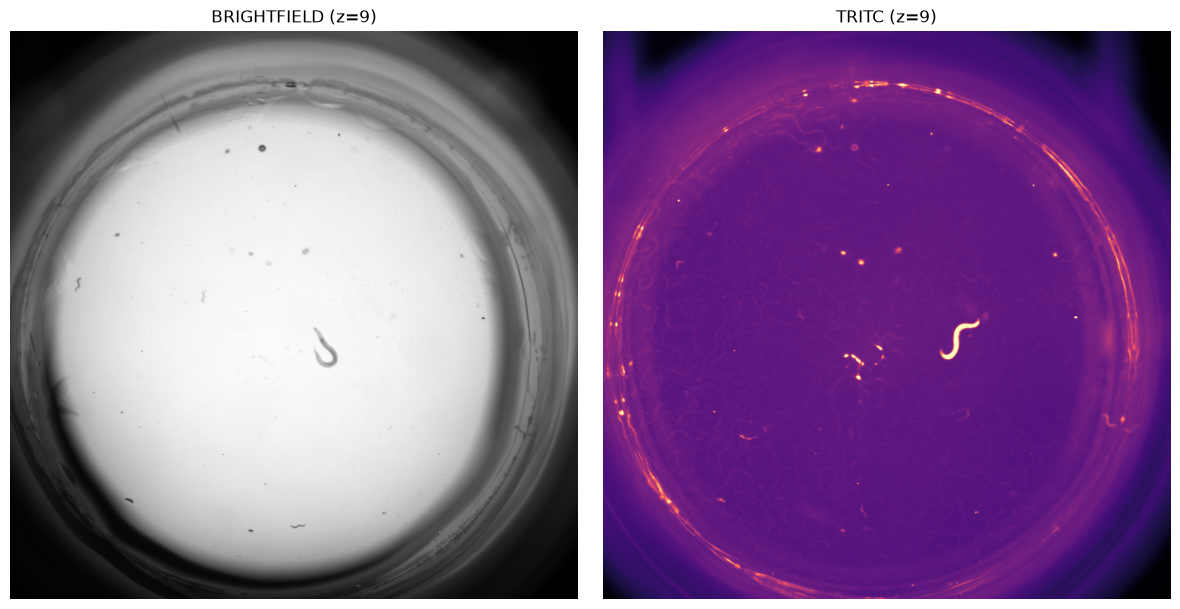

In [7]:
fluor = zstack.get_channel_intensities("TRITC")
fluor_focused_u8 = efs.to_ubyte(preprocess(fluor[focus_index]))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(focused_u8, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"BRIGHTFIELD (z={focus_index})")
axes[1].imshow(fluor_focused_u8, cmap="magma", vmin=0, vmax=255)
axes[1].set_title(f"TRITC (z={focus_index})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Doing this in one line, and at scale

Everything above is bundled into `efs.process_file`, which the CLI calls per file. To reproduce the whole workflow for a directory of ND2 files from the shell:

```bash
uv run python image-processing/extract_focused_slices.py \
    image-processing/data \
    --output-dir image-processing/data/focused \
    --save-fluorescence
```

That walks every `*.nd2` under the input directory, writes the focused brightfield image to the output directory, and (with `--save-fluorescence`) writes the matching TRITC slice under a `fluorescence/` subfolder. Use `--dry-run` to report the detected focus index for each file without writing anything, and `--help` to see all options.